# Chapter 07 제출 답안. 그래프로 데이터의 이야기를 보여주기

## 제출 정보

- 이름: 이성민
- GitHub ID: minilee0307-dot
- 작성·실행일: **2026-10-11**
- 분석 기준일: **2026-10-08** — Chapter 06과 비교할 수 있도록 고정했다.
- 최종 Notebook URL: https://github.com/minilee0307-dot/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb
- 실습 상태: **COMPLETE** — 전체 코드 셀을 순서대로 실행하고 결과를 저장했다.
- GitHub 표시·eTL 접수 상태: **COMPLETE** — 2026-10-11 GitHub의 코드·저장 출력·그래프 7개와 상대 이미지 링크를 확인했고, eTL에서 **2026-10-11 21:36 (Asia/Seoul) 제출됨** 및 최종 Notebook URL 접수를 확인했다. 온라인 확인과 제출은 Codex의 도움을 받았다.

### 핵심 답변

2025-07-02~2026-08-28 양 끝 포함, completed이고 주문일이 유효하며 분석 기준일 이하인 **421상세·175주문·134,523,000원**을 동일하게 사용했다. 금액은 `quantity × unit_price`이며 **정제 후 남은 유효 상세의 합계**다. 날짜·상태 조건을 통과한 주문은 176건이지만 남은 유효 상세가 있는 175건만 금액을 집계했고, 상세가 없는 1건은 평균의 분모에서 제외했다. 일부 상세가 격리된 주문 18건이 포함되어 원래 전체 청구금액과 다를 수 있다. 이 주문을 전부 제외하면 157주문·120,972,000원이다.

금액 1위는 **패션 32,940,000원(24.49%)**이다. 월별 표는 2025-07~2026-08의 14개월이며 누락 월 0개, 관측 금액 0원인 월도 0개다. 상품 가격 분포는 금액 분석과 별개인 **clean 상품 전체 96개**다. 최고 목록 가격 9,999,999원을 포함한 전체와 200,000원 이하 95개 확대를 나란히 그렸다.

공식 [Notebook](https://github.com/GilbertMoon/llm-data-analysis-course/blob/b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc/notebooks/ch07_visualization.ipynb), [실습 가이드](https://github.com/GilbertMoon/llm-data-analysis-course/blob/b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc/practice/chapter07/chapter07.md), [답안 양식](https://github.com/GilbertMoon/llm-data-analysis-course/blob/b1597e10c87f5c461bdb7e3f8f9b8454ba8cbedc/practice/chapter07/templates/chapter07_assignment.md)을 기준으로 작성했다. 공식 흐름의 막대·선·히스토그램·산점도·익명 고객 가로 막대·전체 상태 막대와 bins 비교를 모두 수행했다. [eTL Chapter 07 과제 안내](https://myetl.snu.ac.kr/courses/310975/assignments/384463)와 연결된 [교수님 설명](https://blog.naver.com/dev-dog/224414845375)도 2026-10-11에 확인했다.

코드 작성·실행·LLM 독립 검토·문장 정리에 Codex의 도움을 받았다. 공개 수업용 합성 데이터만 사용했고 고객 이름·원본 고객 ID를 표와 그래프에 출력하지 않았다. 아래 저장된 표·검증 결과·그래프가 실행 Evidence이며 외부 UI 캡처로 꾸미지 않았다.


## 0. 실행 방법과 데이터 보존

입력은 Chapter 05의 `data/processed/*_clean.csv` 4개다. 이번 과제에서는 원본과 clean을 다시 생성하거나 수정하지 않는다. 기존 수업 프로젝트의 Python 3.14.3 가상환경을 재사용했으며 실제 커널과 패키지 버전은 아래에 출력했다.

저장소 루트에서 `python scripts/run_visualization.py`를 실행하거나, 필요한 패키지를 설치한 환경으로 이 Notebook을 전체 실행한다. 출력은 `chapter07/images/graph01~07.png`와 `reports/ch07_*`다. 그래프에 앞서 집계표를 먼저 확인하고, 막대 높이·선의 x/y·히스토그램 도수를 실제 matplotlib artist에서 꺼내 원본 집계와 대조했다.

## 1. 시각화 질문과 그래프 선택

| 질문 | 선택한 그래프 | 선택 이유 | 범위와 지표 |
| --- | --- | --- | --- |
| 카테고리별 완료 주문 상세 금액은 얼마나 다른가? | 금액 내림차순 막대 | 범주별 크기와 실제 차이를 비교하기 좋다 | 2025-07-02~2026-08-28 completed·유효일·기준일 이하, quantity×unit_price 합 |
| 월별 금액은 어떻게 변하는가? | 점을 표시한 선 | 같은 모집단의 시간 순서를 보여 준다 | 같은 금액 모집단, 월별 금액·고유 주문수·남은 상세 기준 평균 주문금액 |
| 상품 목록 가격은 어디에 몰려 있는가? | 전체·확대 히스토그램 | 숫자 구간의 빈도와 극단 후보를 함께 확인한다 | 전체 clean 상품 96개; 확대 95개·범위 밖 1개를 구분 |
| 목록 가격과 판매 수량은 어떤 관계인가? | 산점도 | 한 점을 한 상품으로 두고 두 수치를 비교한다 | 같은 completed 모집단에서 판매된 상품 95개; 목록 price와 판매수량 |
| 상위 구매 고객의 금액은 어떻게 다른가? | 익명 가로 막대 | 순위와 긴 라벨을 읽기 쉽다 | 같은 구매고객 중 금액 Top10; 고유 주문수·평균 함께 확인 |
| 주문 상태별 건수는 어떤가? | 상태별 막대 | 범주별 건수를 직접 비교한다 | 이 그래프만 날짜/상태 필터 전 clean 주문 298건 |

금액 모집단을 서로 다르게 섞지 않았다. 상품 가격은 현재 목록 가격이고 주문 당시 거래 단가와 다르므로 별도 질문으로 다뤘다.

In [1]:
from pathlib import Path
import sys, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')  # 화면 창을 열지 않고 파일로 그린다.
from IPython.display import display, Image

CURRENT_DIR=Path.cwd()
PROJECT_ROOT=next((p for p in [CURRENT_DIR,*CURRENT_DIR.parents]
    if (p/'scripts'/'run_visualization.py').is_file() and (p/'data'/'processed').is_dir()),None)
assert PROJECT_ROOT is not None
PROCESSED_DIR=PROJECT_ROOT/'data'/'processed'
REPORT_DIR=PROJECT_ROOT/'reports'
FIGURE_DIR=PROJECT_ROOT/'chapter07'/'images'
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
print('Python:',sys.version.split()[0],'pandas:',pd.__version__,'NumPy:',np.__version__,'matplotlib:',matplotlib.__version__)
print('실제 커널:',sys.executable)
print('입력: data/processed; 이미지: chapter07/images; 집계: reports/ch07_*')
input_hashes={str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
    for folder in ['raw','processed'] for p in sorted((PROJECT_ROOT/'data'/folder).glob('*.csv'))}
print('보존할 raw/clean CSV:',len(input_hashes),'개')

Python: 3.14.3 pandas: 3.0.5 NumPy: 2.5.3 matplotlib: 3.11.1
실제 커널: /Users/sungmiiinn/Desktop/LLM을 활용한 빅데이터 분석/llm-data-analysis-course/.venv/bin/python
입력: data/processed; 이미지: chapter07/images; 집계: reports/ch07_*
보존할 raw/clean CSV: 8 개


## 2. 집계표와 검증을 먼저 확인 — Evidence E01

필수 컬럼·숫자형·PK/FK·many_to_one 병합과 행 수, completed·날짜 범위, 공통 금액 총합을 먼저 점검했다. Chapter 06의 검증된 EDA 모듈을 재사용하고 상품·달력·상태·히스토그램 표본 검증을 추가했다.

In [2]:
from src.visualization import (prepare_visualization_data,setup_korean_font,
    plot_category_sales,plot_monthly_sales,plot_product_price_hist,
    plot_price_quantity_scatter,plot_top_customers,plot_order_status,
    plot_bins_comparison,create_all_figures,create_visualization_summary,
    save_visualization_outputs,build_visualization_report)
font=setup_korean_font()
assert Path(font['font_path']).is_file()
print('한글 폰트:',font['font_family'])
print('실제 폰트 파일:',font['font_path'])
viz_data=prepare_visualization_data(PROCESSED_DIR)
products=viz_data['products'];orders=viz_data['orders']
completed_order_sales=viz_data['completed_order_sales']
category_sales=viz_data['category_sales'];monthly_sales=viz_data['monthly_sales']
product_sales=viz_data['product_sales'];customer_sales=viz_data['customer_sales']
order_status=viz_data['order_status'];chart_checks=[]
display(viz_data['source_files'])
display(viz_data['eda_results']['scope'])
display(viz_data['eda_results']['partial_sensitivity'])

한글 폰트: AppleGothic
실제 폰트 파일: /System/Library/Fonts/Supplemental/AppleGothic.ttf


,파일,행,열
0,customers_clean.csv,150,11
1,products_clean.csv,96,5
2,orders_clean.csv,298,10
3,order_items_clean.csv,724,7


,범위,상세행수,주문수,금액합계,주석
0,전체 clean 상세 (매출 아님),724,297,244374000,
1,completed 전체,430,178,137335000,
2,completed 날짜 결측 제외,6,2,1903000,금액분석의 공통 제외
3,completed 미래 후보 제외,3,1,909000,기준일 이후를 공통 제외
4,최종 분석 모집단,421,175,134523000,금액 상세가 없는 조건충족 주문 1건; 평균 분모 제외


,분석 범위,상세행수,주문수,금액합계,남은상세 주문금액평균
0,남은 유효 상세 포함 (기본),421,175,134523000,768702.857143
1,일부 상세 제외 주문 전부 제외,377,157,120972000,770522.292994


In [3]:
display(viz_data['visualization_validation'])
assert viz_data['visualization_validation'].passed.all()
print('집계 검증:',len(viz_data['visualization_validation']),'/',len(viz_data['visualization_validation']),'PASS')

,check,actual,expected,passed
0,FK customer_id,0,0,True
1,FK order_id,0,0,True
2,FK product_id,0,0,True
3,orders 병합 행 증가,0,0,True
4,products 병합 행 증가,0,0,True
5,customers 병합 행 증가,0,0,True
6,집계 전 clean 독립 계산 합계,134523000,134523000,True
7,병합 상세 합계,134523000,134523000,True
8,카테고리 합계,134523000,134523000,True
9,월 합계,134523000,134523000,True


집계 검증: 20 / 20 PASS


### 검증 결과와 진행 판단

**관찰**: 집계 검증 20개가 모두 True였다. 같은 범위의 clean 상세·카테고리·월·상품·고객 합계는 134,523,000원이며 병합으로 늘어난 행이나 미연결 FK가 없다. 날짜 결측 완료 상세 6행·1,903,000원, 미래 후보 완료 상세 3행·909,000원은 모든 금액 그래프에서 공통 제외했다.

**판단**: 금액 기준과 집계가 일치하여 시각화를 진행했다. 다만 일부 상세가 제외된 주문 18건이 남아 있으므로 금액은 남은 유효 상세의 합계로 읽는다. 전체 제외 민감도는 위 표에 실제 계산했다. 누락 값을 복원하거나 거래의 정당성을 확정한 것은 아니다.

## 2-1. 대표 그래프 1 — 카테고리 막대 / Evidence E02

범주별 크기 비교에 맞게 금액 내림차순으로 정렬하고 값 축을 0에서 시작했다. 원본 집계표를 먼저 출력했다.

In [4]:
display(category_sales[['category','total_quantity','completed_amount','amount_ratio_pct']])
assert category_sales.completed_amount.sum()==completed_order_sales.line_total.sum()

,category,total_quantity,completed_amount,amount_ratio_pct
6,패션,290,32940000,24.49
4,식품,220,24731000,18.38
5,전자기기,172,20445000,15.20
1,뷰티,176,17166000,12.76
0,도서,168,16895000,12.56
3,스포츠,165,13237000,9.84
2,생활용품,125,9109000,6.77


,그래프 검증,실제값,기대값,통과
0,bar heights,134523000.0,134523000,True
1,범주 순서,7.0,7,True
2,값 축 시작,0.0,0,True


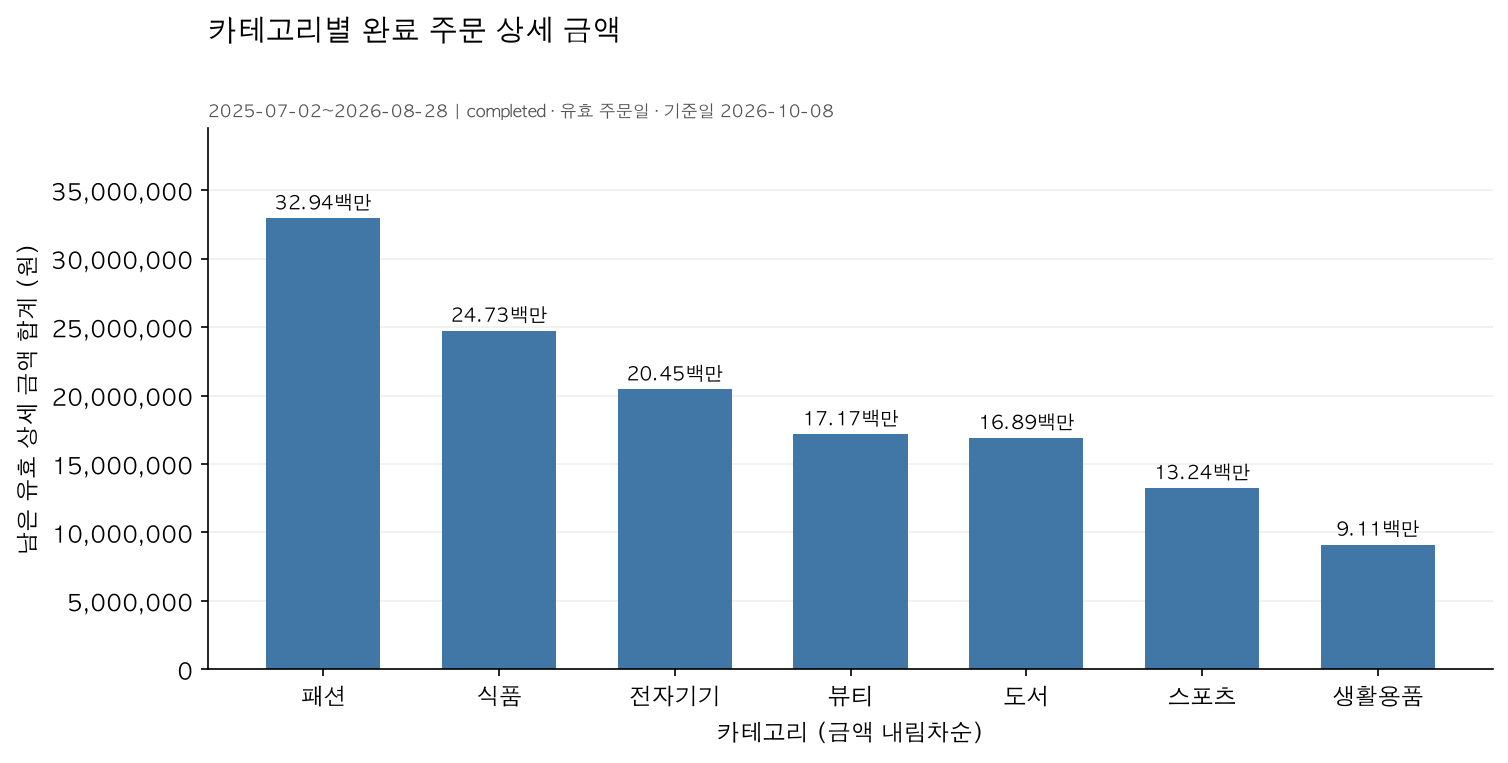

In [5]:
chart1=plot_category_sales(category_sales,FIGURE_DIR/'graph01.png',show=False,data_range=viz_data['date_range'])
display(chart1.validation);chart_checks.append(chart1.validation.assign(graph='category_sales'))
display(Image(filename=str(chart1.path)))

### 원본 집계값

카테고리 7개의 금액 합계는 134,523,000원이다. 패션 32,940,000원(24.49%), 생활용품 9,109,000원(6.77%)이며 차이는 23,831,000원이다. 전체 값은 위 집계표와 막대 높이 검증에 있다. 저장 파일: [graph01.png](images/graph01.png).

### 결과 관찰

패션이 가장 크고 생활용품이 가장 작다. 패션의 수량은 290개다. 막대 7개의 높이를 집계표의 7개 값과 각각 대조해 모두 일치했다.

### 나의 해석과 판단

금액의 순위를 보여 주는 그래프다. 상품이 더 인기 있거나 이익이 크다는 판단까지 넓히지 않았다. 금액 차이는 판매 수량과 거래 단가를 함께 보아야 한다.

### 업무·분석적 의미

패션과 다른 카테고리의 거래 구성을 다음 분석의 우선 비교 대상으로 삼을 수 있다.

### 한계와 추가 확인 사항

원가·할인·광고·재고가 없고 일부 주문에는 격리된 상세가 있다. 원래 청구총액이나 카테고리의 수익성을 뜻하지 않는다.

**다음 질문**: 카테고리 금액 차이는 판매 수량과 수량가중 거래 단가에서 각각 어떻게 나타나는가?

## 3. 대표 그래프 2 — 월별 선 / Evidence E03

시간 정렬과 연속 달력을 확인했다. 누락 월을 임의의 0으로 채우지 않는다. 실제 데이터는 14개월 모두 관측되었고 금액은 모두 양수다. 경계 월의 수집 완전성은 확인되지 않았다고 제목 아래에 표시했다.

In [6]:
display(monthly_sales)
print('달력 월 수:',len(monthly_sales))
print('관측 안 된 월:',int((~monthly_sales.observed_in_selected_data).sum()))
print('관측된 0원 월:',int(monthly_sales.zero_amount_observed.sum()))

,order_month,completed_amount,completed_order_count,average_completed_order_amount,month_start,observed_in_selected_data,zero_amount_observed
0,2025-07,9479000,11,8.617273e+05,2025-07-01,True,False
1,2025-08,8892000,17,5.230588e+05,2025-08-01,True,False
2,2025-09,4519000,4,1.129750e+06,2025-09-01,True,False
3,2025-10,12547000,17,7.380588e+05,2025-10-01,True,False
4,2025-11,9163000,16,5.726875e+05,2025-11-01,True,False
5,2025-12,8113000,12,6.760833e+05,2025-12-01,True,False
6,2026-01,7759000,8,9.698750e+05,2026-01-01,True,False
7,2026-02,7689000,12,6.407500e+05,2026-02-01,True,False
8,2026-03,7493000,13,5.763846e+05,2026-03-01,True,False
9,2026-04,11459000,14,8.185000e+05,2026-04-01,True,False


달력 월 수: 14
관측 안 된 월: 0
관측된 0원 월: 0


,그래프 검증,실제값,기대값,통과
0,line y,134523000.0,134523000.0,True
1,line x 달력,14.0,14.0,True
2,시간 정렬,1.0,1.0,True
3,누락 월을 0으로 채우지 않음,0.0,0.0,True


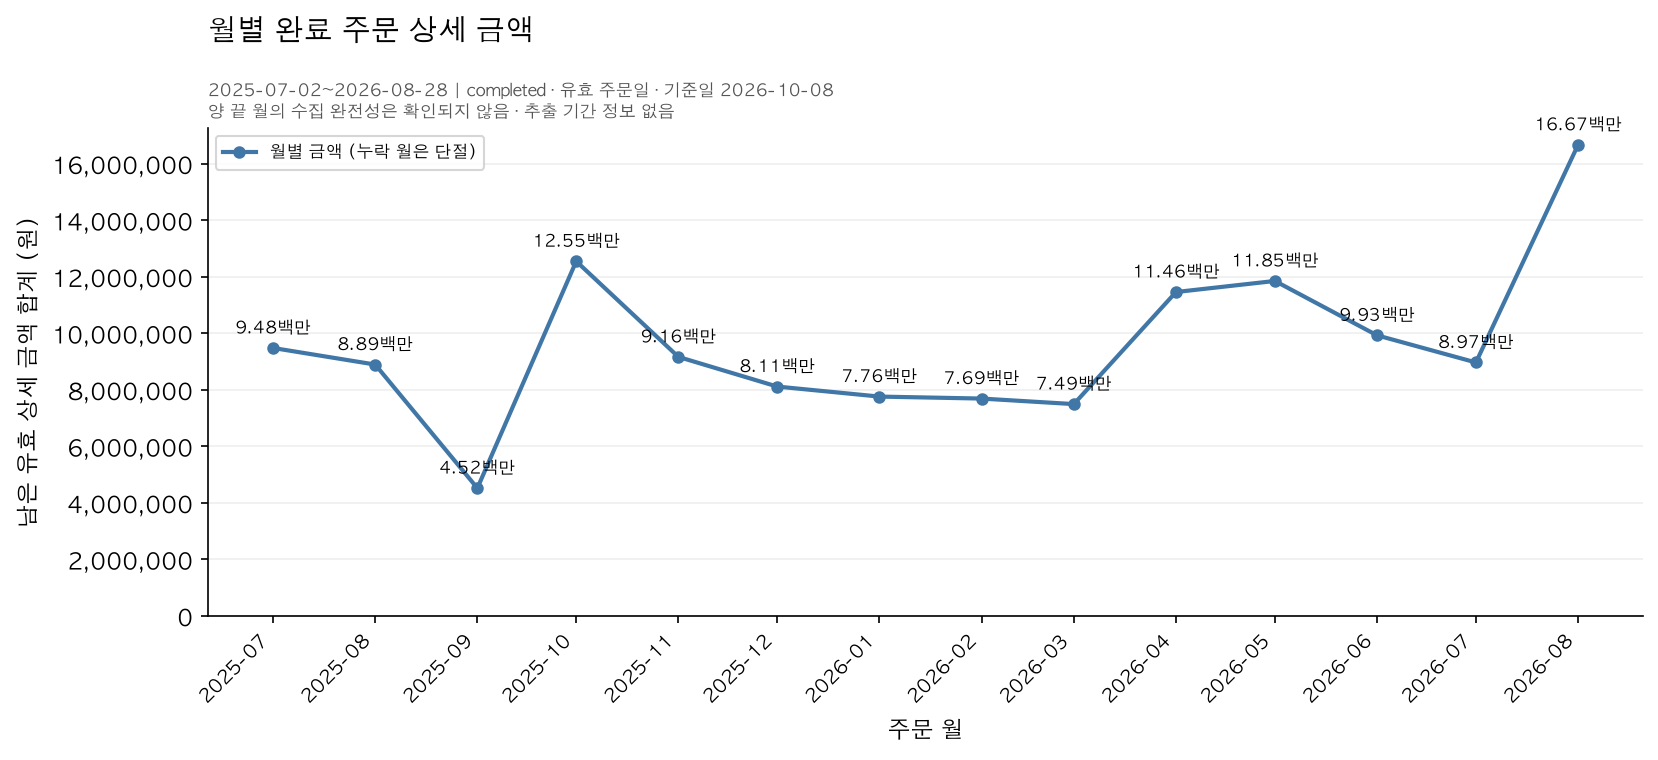

In [7]:
chart2=plot_monthly_sales(monthly_sales,FIGURE_DIR/'graph02.png',show=False,data_range=viz_data['date_range'])
display(chart2.validation);chart_checks.append(chart2.validation.assign(graph='monthly_sales'))
display(Image(filename=str(chart2.path)))

### 원본 집계값

2025-07~2026-08의 14개 월 합계가 134,523,000원이다. 최대는 2026-08 16,668,000원, 최소는 2025-09 4,519,000원이다. 선의 x좌표를 월 시작일과, y좌표를 월별 금액과 각각 대조했다. 저장 파일: [graph02.png](images/graph02.png).

### 결과 관찰

금액은 매월 계속 증가하거나 감소하지 않고 오르내린다. 최대 월 2026-08의 금액 있는 주문은 15건, 남은 상세 기준 평균 주문금액은 1,111,200원이다. 최소 월 2025-09은 4건, 평균 1,129,750원이다.

### 나의 해석과 판단

증감을 하나의 원인으로 설명하기 전에 주문 건수와 평균 주문금액을 나누어 보았다. 실제 거래일의 최소·최대로 분석 기간을 정했으므로 경계 월의 관측 조건이 같다고 가정하지 않았다.

### 업무·분석적 의미

월별 금액이 달라지는 구간을 찾고, 월×카테고리 금액과 주문 수를 추가 비교하는 출발점이 된다.

### 한계와 추가 확인 사항

추출 시작·종료일이 없어 경계 월의 전체 수집 여부는 모른다. 광고·계절성·고객 이탈의 원인은 현재 그래프만으로 알 수 없으며 14개월 표만으로 안정적인 추세를 확정하지 않는다.

**다음 질문**: 금액 차이가 큰 두 월에서 주문 수, 남은 상세 기준 평균 주문금액, 카테고리 구성이 함께 어떻게 달라졌는가?

## 4. 대표 그래프 3 — 상품 가격 히스토그램 / Evidence E04

상품 마스터의 분포라 주문 상태와 무관하게 전체 상품을 사용한다. 전체 96개를 먼저 보여 주고 통상 가격 구간 95개를 확대했다. 확대 범위 밖 1개는 삭제하지 않고 전체 패널과 주석에 남겼다.

In [8]:
display(products.price.describe().to_frame('전체 목록가격'))
price_scope=pd.DataFrame([['전체',len(products),products.price.min(),products.price.max(),products.price.median()],
 ['0~200000원 확대',int(products.price.between(0,200000).sum()),products.loc[products.price.between(0,200000),'price'].min(),products.loc[products.price.between(0,200000),'price'].max(),products.loc[products.price.between(0,200000),'price'].median()]],columns=['범위','상품수','최소(원)','최대(원)','중앙값(원)'])
display(price_scope)
display(viz_data['histogram_table'].loc[viz_data['histogram_table'].bins.eq(20)])

,전체 목록가격
count,9.600000e+01
mean,2.048958e+05
std,1.011848e+06
min,5.000000e+03
25%,5.275000e+04
50%,9.450000e+04
75%,1.532500e+05
max,9.999999e+06


,범위,상품수,최소(원),최대(원),중앙값(원)
0,전체,96,5000,9999999,94500.0
1,0~200000원 확대,95,5000,197000,93000.0


,표본,bins,구간,하한(포함),상한(마지막구간만 포함),상품수
10,전체 상품,20,0,5000.00,504749.95,95
11,전체 상품,20,1,504749.95,1004499.90,0
12,전체 상품,20,2,1004499.90,1504249.85,0
13,전체 상품,20,3,1504249.85,2003999.80,0
14,전체 상품,20,4,2003999.80,2503749.75,0
15,전체 상품,20,5,2503749.75,3003499.70,0
16,전체 상품,20,6,3003499.70,3503249.65,0
17,전체 상품,20,7,3503249.65,4002999.60,0
18,전체 상품,20,8,4002999.60,4502749.55,0
19,전체 상품,20,9,4502749.55,5002499.50,0


,그래프 검증,실제값,기대값,통과
0,전체 hist counts,96,96,True
1,확대 hist counts,95,95,True
2,전체=확대+밖,96,96,True


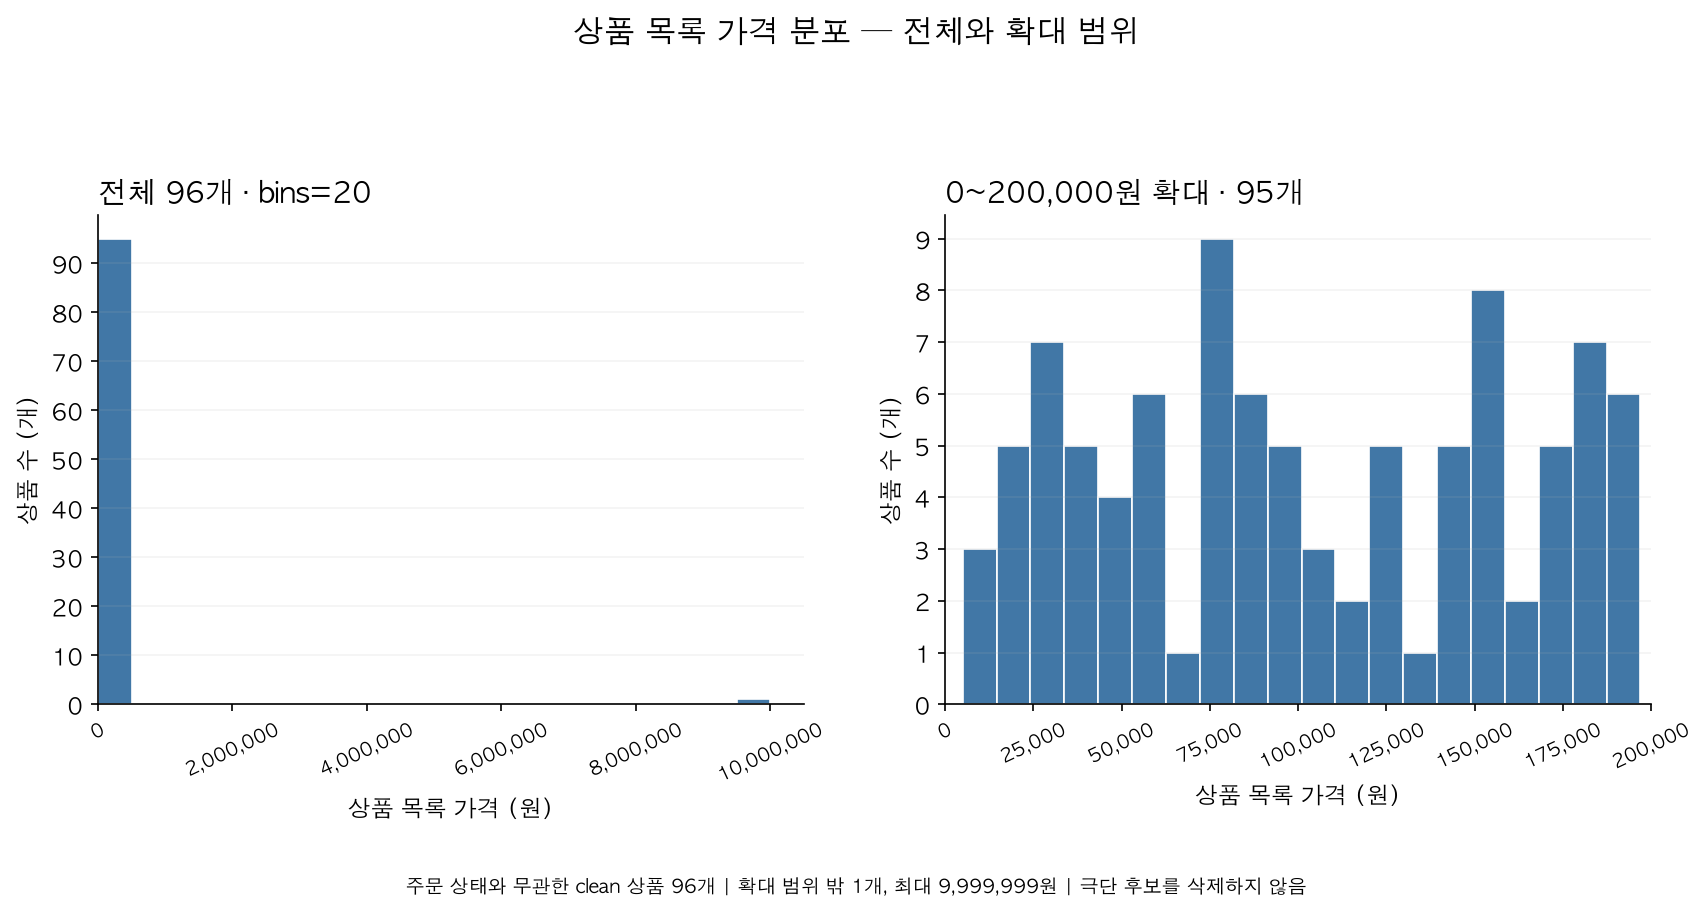

In [9]:
chart3=plot_product_price_hist(products,FIGURE_DIR/'graph03.png',show=False,bins=20)
display(chart3.validation);chart_checks.append(chart3.validation.assign(graph='product_price'))
display(Image(filename=str(chart3.path)))

### 원본 집계값

전체 96개, 최소 5,000원·중앙값 94,500원·최대 9,999,999원이다. 200,000원 이하 확대는 95개, 중앙값 93,000원·최대 197,000원이다. 범위 밖은 1개다. bins=20 도수 합이 각각 96과 95이며 최대값도 마지막 구간에 포함된다. 저장 파일: [graph03.png](images/graph03.png).

### 결과 관찰

전체 범위에서는 95개가 첫 구간에 모이고 고가 후보 1개가 마지막 구간에 있다. 확대 범위에서는 5,000~197,000원의 분포를 구분해 볼 수 있다.

### 나의 해석과 판단

전체 그림 하나만 보면 일반 가격대의 차이가 거의 보이지 않는다. 그래서 극단 후보를 숨기지 않고 전체·확대를 함께 표시했다. 95개 확대를 전체 상품 분포라고 부르지 않았다.

### 업무·분석적 의미

목록 가격 9,999,999원이 실제 상품 설정인지 입력 문제인지 원천 확인이 먼저 필요하다. 통상 구간의 상품 구성을 살피는 데는 확대 그림이 도움이 된다.

### 한계와 추가 확인 사항

고가 후보가 오류인지 이 데이터만으로 확정할 수 없다. 상품 목록 price는 거래 unit_price와 다르며 이 후보를 실제 고액 주문으로 해석하지 않는다. bins에 따라 모양도 달라진다.

**다음 질문**: bins=10·20·30에서도 전체와 확대 표본의 어떤 패턴이 유지되고 어떤 모양이 달라지는가?

## 4-1. bins=10·20·30 실제 비교

같은 상품 표본으로 구간 수만 바꿨다. 각 열의 첫 행은 전체 96개, 둘째 행은 같은 확대 부분집합 95개이며 범위 밖 1개를 명시했다.

,표본,bins,상품수
0,0~200000원 확대,10,95
1,0~200000원 확대,20,95
2,0~200000원 확대,30,95
3,전체 상품,10,96
4,전체 상품,20,96
5,전체 상품,30,96


,그래프 검증,실제값,기대값,통과
0,전체 96개 bins=10 hist counts,96,96,True
1,전체 96개 bins=20 hist counts,96,96,True
2,전체 96개 bins=30 hist counts,96,96,True
3,확대 95개 · 범위 밖 1개 bins=10 hist counts,95,95,True
4,확대 95개 · 범위 밖 1개 bins=20 hist counts,95,95,True
5,확대 95개 · 범위 밖 1개 bins=30 hist counts,95,95,True


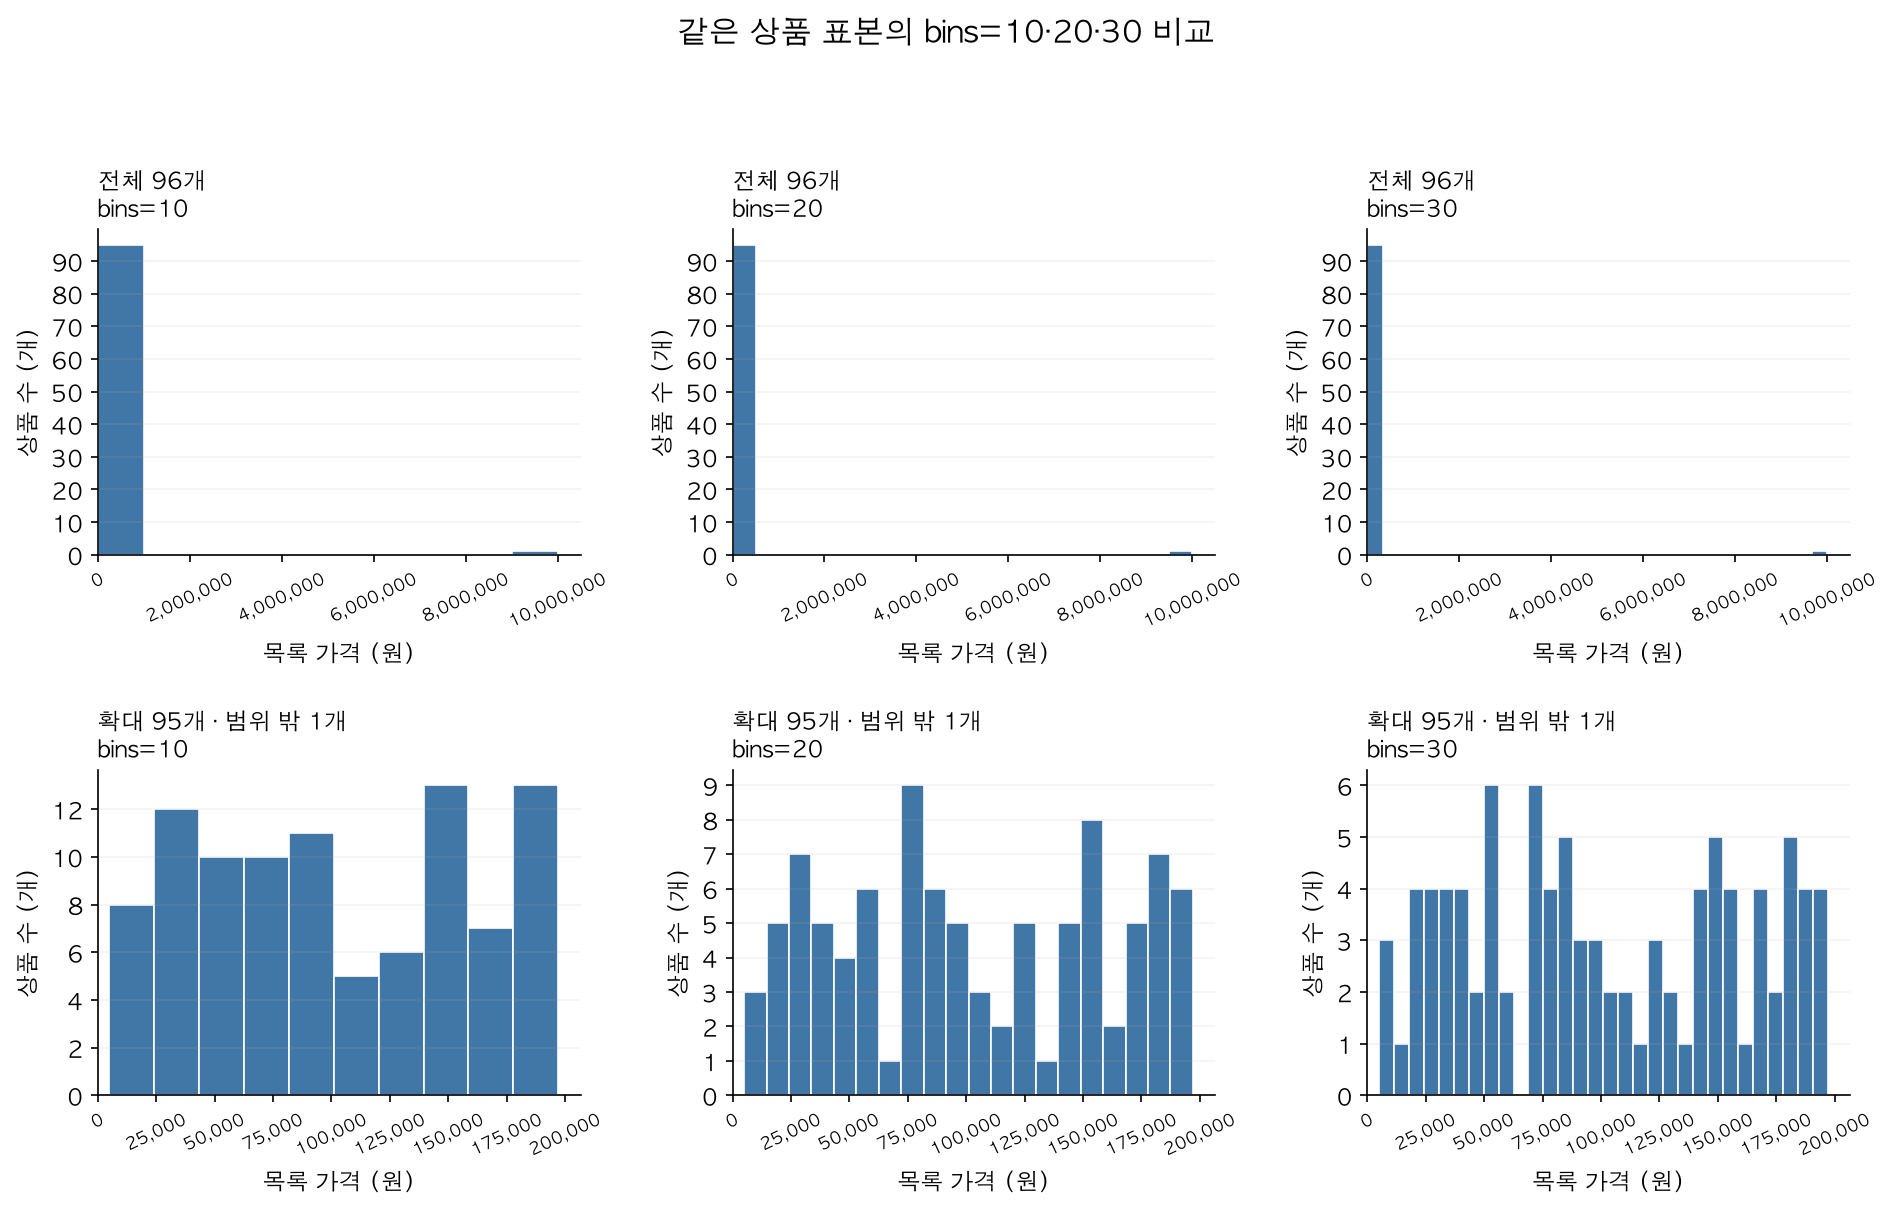

In [10]:
display(viz_data['histogram_table'].groupby(['표본','bins'],as_index=False).상품수.sum())
chart7=plot_bins_comparison(products,FIGURE_DIR/'graph07.png',show=False)
display(chart7.validation);chart_checks.append(chart7.validation.assign(graph='bins_comparison'))
display(Image(filename=str(chart7.path)))

### bins 비교의 관찰과 판단

전체 96개의 분포는 bins=10·20·30 모두 첫 구간 95개·마지막 구간 1개로 압축된다. 고가 후보 때문에 일반 가격대가 잘 보이지 않는 패턴은 유지된다. 확대 95개는 구간 수에 따라 봉우리와 빈 구간의 모양이 달라져, 구간 하나만 보고 가격대의 특징이나 이상값을 확정하지 않았다. 도수 합은 전체 96·확대 95로 각각 검증했다. 저장 파일: [graph07.png](images/graph07.png).

## 4-2. 추가 그래프 — 목록 가격과 완료 주문 판매 수량 산점도

한 점은 현재 모집단에서 판매된 상품 1개다. 목록 가격과 수량의 관계가 있어 보여도 가격의 인과효과라고 해석하지 않는다.

,category,price,completed_quantity,completed_amount
70,스포츠,183000,37,6771000
90,패션,96000,70,6720000
91,패션,187000,26,4862000
61,식품,193000,24,4632000
50,전자기기,152000,26,3952000
66,패션,168000,21,3528000
36,뷰티,172000,17,2924000
45,식품,171000,17,2907000
47,패션,183000,15,2745000
81,전자기기,145000,18,2610000


판매 상품 점 수: 95  / 전체 상품: 96


,그래프 검증,실제값,기대값,통과
0,전체 scatter xy,95,95,True
1,"0~200,000원 확대 scatter xy",94,94,True


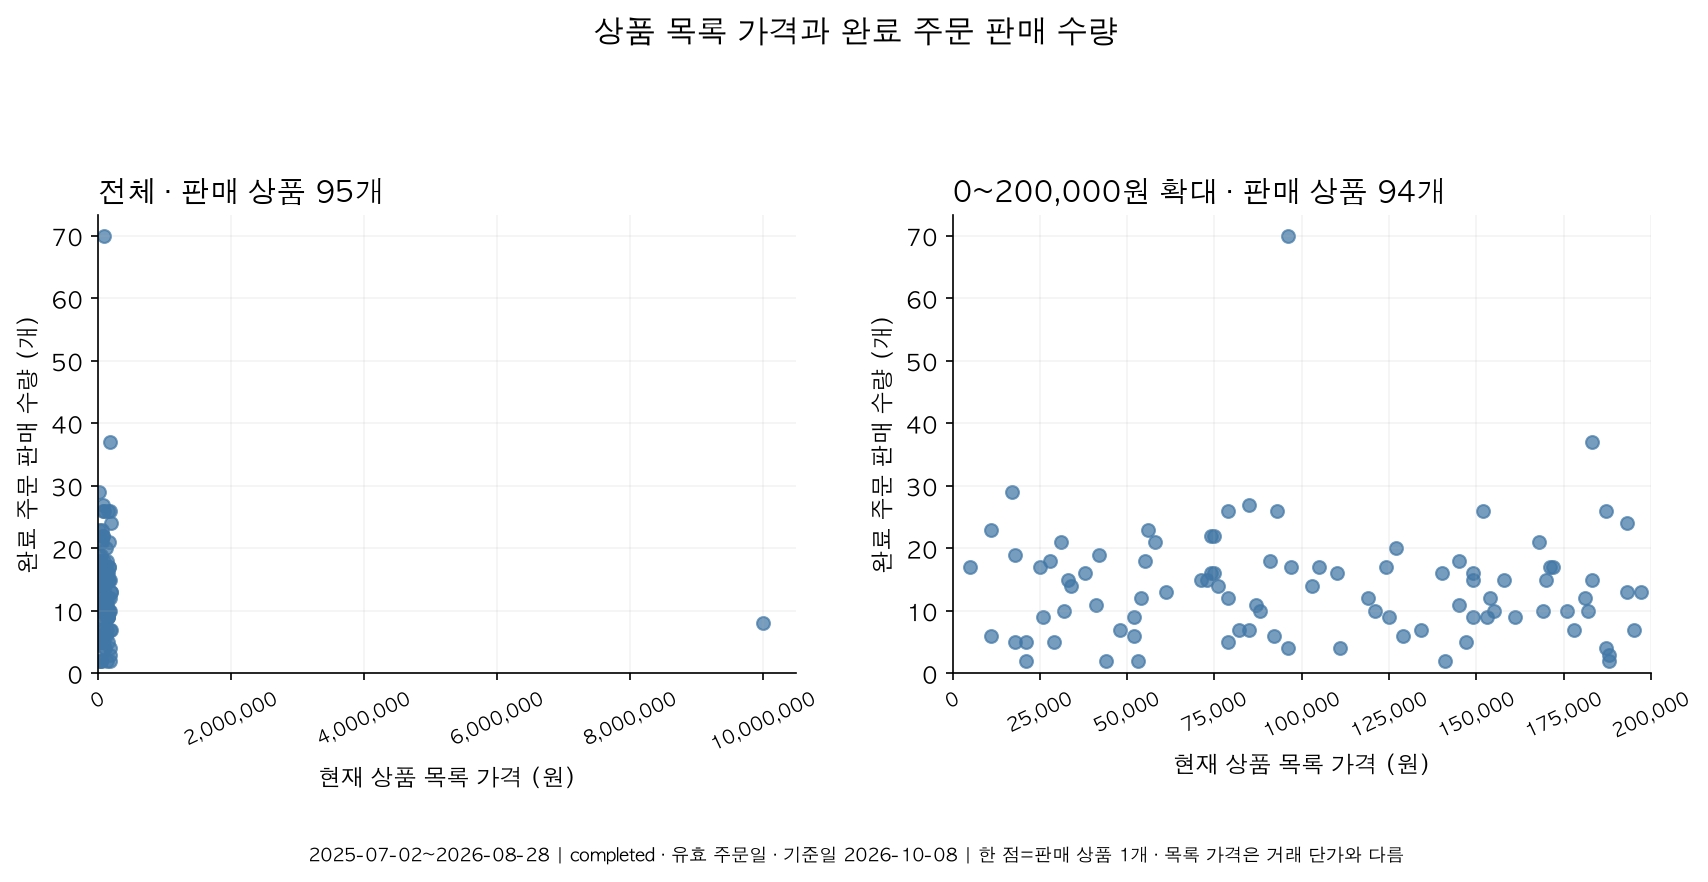

In [11]:
display(product_sales[['category','price','completed_quantity','completed_amount']].head(10))
print('판매 상품 점 수:',len(product_sales),' / 전체 상품:',len(products))
chart4=plot_price_quantity_scatter(product_sales,FIGURE_DIR/'graph04.png',show=False,data_range=viz_data['date_range'])
display(chart4.validation);chart_checks.append(chart4.validation.assign(graph='price_quantity'))
display(Image(filename=str(chart4.path)))

### 원본 집계값

판매 상품 95개가 점 95개가 된다. 각 점의 x=목록 price, y=completed 판매수량을 집계표와 대조했다. 확대 부분집합의 점 수도 별도 검증했다. 저장 파일: [graph04.png](images/graph04.png).

### 결과 관찰

고가 후보 때문에 전체 x축에서는 일반 가격대 점들이 좁게 모여 보인다. 확대에서는 가격대별 수량 차이를 더 구분할 수 있다.

### 나의 해석과 판단

목록 가격과 판매수량의 기술적 관계를 살폈다. 확대 그림의 인상만으로 관계가 강하다거나 가격을 낮추면 수량이 늘어난다고 결론 내리지 않았다.

### 업무·분석적 의미

가격대와 카테고리를 구분한 후속 비교의 출발점이 된다.

### 한계와 추가 확인 사항

카테고리·노출·재고·할인과 실제 거래 단가의 차이를 통제하지 않았다. 판매가 없는 상품 1개는 판매 상품 집계에 포함되지 않는다.

**다음 질문**: 같은 카테고리 안에서도 목록 가격과 거래 단가, 판매수량의 관계가 비슷한가?

## 4-3. 추가 그래프 — 금액 상위 고객의 익명 가로 막대

표와 그래프 모두 순위 기반 라벨을 사용하고 고객 이름과 원본 고객 ID는 출력하지 않는다.

In [12]:
display(customer_sales.head(10))
print('전체 구매 고객:',len(customer_sales),' / 표시 고객:10')

,customer_label,completed_order_count,completed_amount,average_completed_order_amount,customer_group
0,구매금액 순위 01,3,6702000,2.234000e+06,반복 구매 (2회 이상)
1,구매금액 순위 02,4,5122000,1.280500e+06,반복 구매 (2회 이상)
2,구매금액 순위 03,3,4311000,1.437000e+06,반복 구매 (2회 이상)
3,구매금액 순위 04,6,3977000,6.628333e+05,반복 구매 (2회 이상)
4,구매금액 순위 05,2,3966000,1.983000e+06,반복 구매 (2회 이상)
5,구매금액 순위 06,4,3845000,9.612500e+05,반복 구매 (2회 이상)
6,구매금액 순위 07,4,3808000,9.520000e+05,반복 구매 (2회 이상)
7,구매금액 순위 08,4,3656000,9.140000e+05,반복 구매 (2회 이상)
8,구매금액 순위 09,4,3201000,8.002500e+05,반복 구매 (2회 이상)
9,구매금액 순위 10,4,2832000,7.080000e+05,반복 구매 (2회 이상)


전체 구매 고객: 96  / 표시 고객:10


,그래프 검증,실제값,기대값,통과
0,barh widths,41420000.0,41420000,True
1,익명 라벨 수,10.0,10,True
2,값 축 시작,0.0,0,True


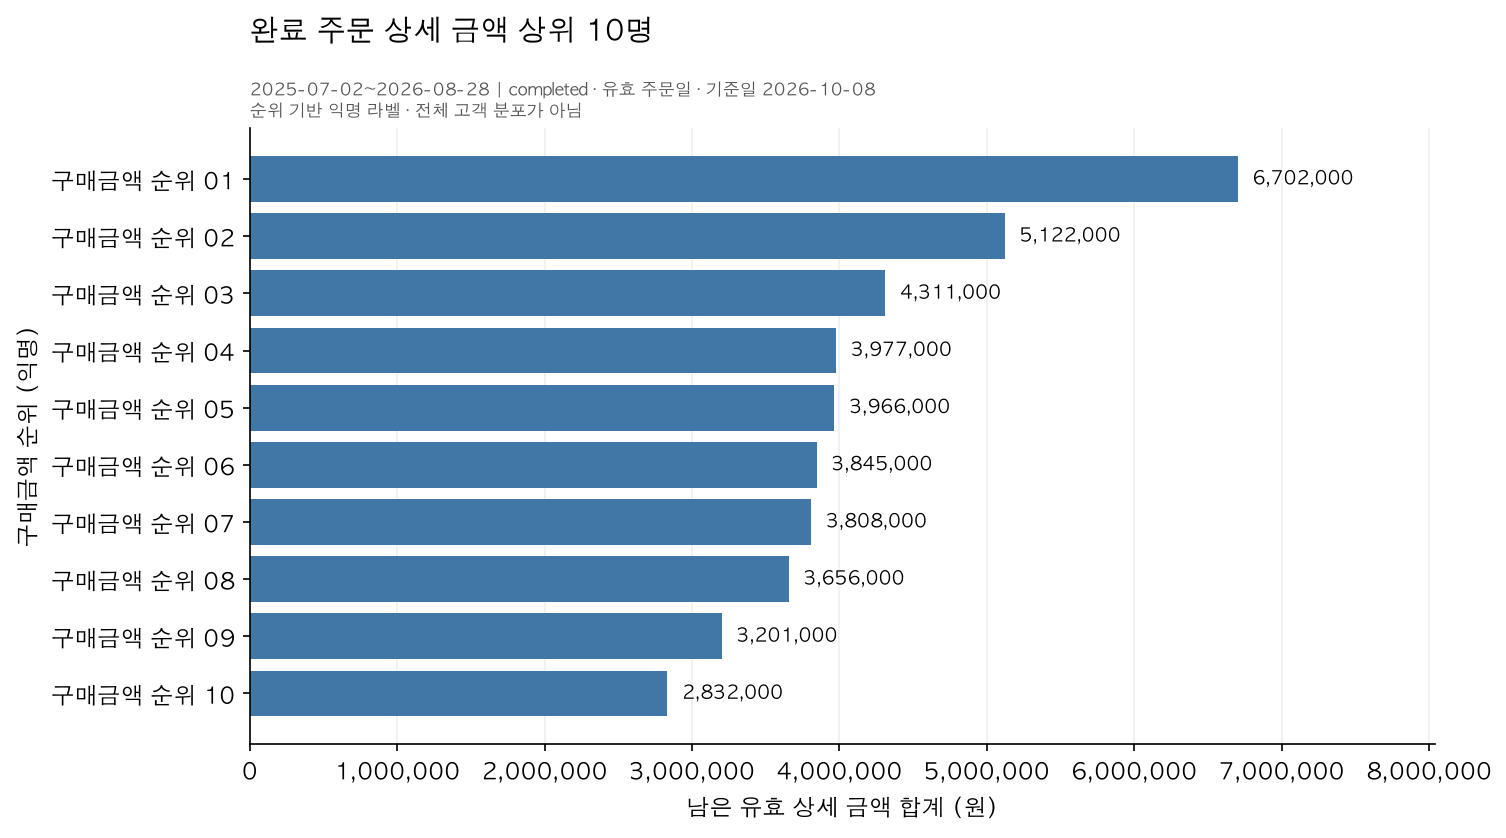

In [13]:
chart5=plot_top_customers(customer_sales,FIGURE_DIR/'graph05.png',show=False,top_n=10,data_range=viz_data['date_range'])
display(chart5.validation);chart_checks.append(chart5.validation.assign(graph='top_customers'))
display(Image(filename=str(chart5.path)))

### 원본 집계값

구매고객 96명 중 금액 상위 10명의 합계는 41,420,000원, 전체 금액의 30.79%다. 고유 주문 수·총금액·평균은 위 표에 함께 표시했다. 가로 막대 너비도 개별 값과 대조했다. 저장 파일: [graph05.png](images/graph05.png).

### 결과 관찰

상위 10명은 모두 기간 내 2~6회 반복 구매 고객이며 평균 주문금액은 서로 다르다. 이 Top10 표에서는 고액 1회 고객이 관찰되지 않았다.

### 나의 해석과 판단

금액이 높다고 바로 충성 고객이라고 부르지 않았다. 상위 10명만 보여 주는 그래프여서 전체 고객 분포도 아니다.

### 업무·분석적 의미

반복 구매 고객과 고액 1회 고객을 나누어 후속 질문을 정할 수 있다.

### 한계와 추가 확인 사항

관측기간 밖 주문과 미래 재구매를 모른다. 일부 주문의 금액은 남은 유효 상세 기준이다.

**다음 질문**: 기간과 고액 구분 기준을 바꾸어도 고객 유형이 비슷하게 유지되는가?

## 4-4. 추가 그래프 — 전체 clean 주문 상태

이 그래프는 날짜와 completed 필터 전인 전체 clean 주문 298건의 상태 분포다. 금액 그래프의 모집단과 구분했다.

In [14]:
display(order_status)
assert order_status.order_count.sum()==len(orders)

,order_status,order_count,ratio_pct
0,completed,179,60.07
1,cancelled,62,20.81
2,refunded,57,19.13


,그래프 검증,실제값,기대값,통과
0,status bar heights,298.0,298,True
1,값 축 시작,0.0,0,True


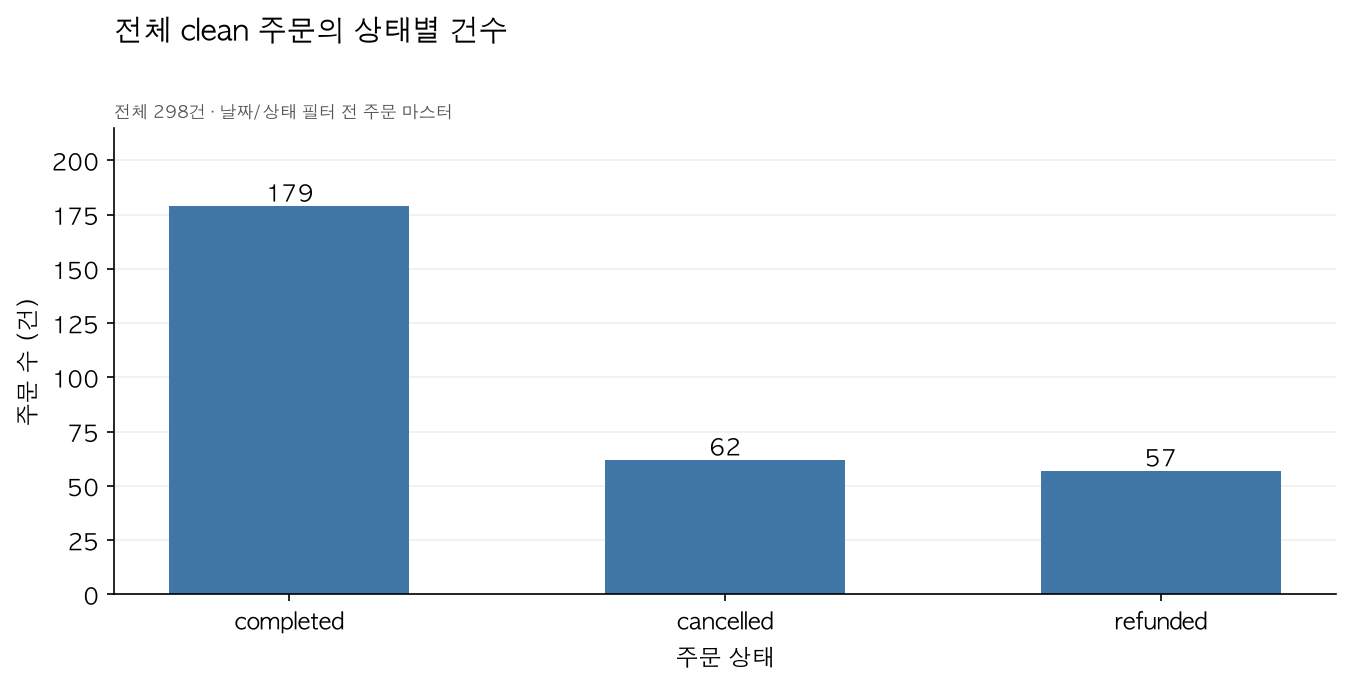

In [15]:
chart6=plot_order_status(order_status,FIGURE_DIR/'graph06.png',show=False)
display(chart6.validation);chart_checks.append(chart6.validation.assign(graph='order_status'))
display(Image(filename=str(chart6.path)))

### 원본 집계값

상태별 건수와 비율은 위 표에 있다. 세 상태의 건수 합이 clean 주문 298건과 같고, 각 막대 높이를 상태별 건수와 대조했다. 저장 파일: [graph06.png](images/graph06.png).

### 결과 관찰

completed, cancelled, refunded 세 상태가 존재하며 completed가 가장 많다.

### 나의 해석과 판단

여기서는 상태별 규모를 비교했다. 취소·환불을 포함한 전체 주문 수를 completed 금액의 분모로 사용하지 않았다.

### 업무·분석적 의미

거래 상태별 후속 품질 점검이나 취소·환불 분석의 기준 분포가 된다.

### 한계와 추가 확인 사항

상태만으로 취소·환불 사유와 처리 시점을 알 수 없고, 환불 이후 실제 정산 금액도 계산할 수 없다.

**다음 질문**: 상태별 상품·결제수단 구성 차이는 어떤가? 사유와 처리일이 추가되면 무엇을 확인할 수 있을까?

## 5. 그래프 정확성 점검

- [x] 실제 막대 높이·선 좌표·히스토그램 도수·산점도 좌표를 원본 표와 대조했다.
- [x] 각 축의 의미와 원/개/건 단위를 표시했다.
- [x] 선의 범례와 상품 전체/확대 범위를 표시했다.
- [x] 카테고리는 금액 내림차순, 월은 시간 오름차순으로 정렬했다.
- [x] 막대의 값 축은 0에서 시작하며 값을 잘라 차이를 과장하지 않았다.
- [x] 금액 그래프 제목에 동일 기간·completed·기준일을 표시했다.
- [x] 누락 월 NaN과 실제 관측 금액 0을 구분했다.
- [x] 고객 이름과 원본 고객 ID를 공개 표·차트에 표시하지 않았다.

### 내가 발견한 시각화 위험 또는 개선점

가장 큰 위험은 고가 후보를 숨기거나 전체 96개와 확대 95개를 같은 표본처럼 읽는 것이다. 전체와 확대를 함께 보여 주고 표본 수를 각각 적었다. 월별 증감을 수요나 광고의 원인으로 해석하는 문제도 있어 경계 월 수집 한계를 남겼다.

## 5-1. 공통 함수로 그래프와 보고서 재생성 — Evidence E05

개별 함수에서 확인한 표와 그래프를 공통 함수와 스크립트로 다시 생성했다. 모든 집계·artist 검증 결과, 원본 보존과 산출물 해시를 아래에 확인했다.

In [16]:
saved_figures,all_artist_checks=create_all_figures(viz_data,FIGURE_DIR,show=False)
assert all_artist_checks['통과'].all()
display(all_artist_checks)
summary=create_visualization_summary(viz_data)
saved_csv=save_visualization_outputs(viz_data,REPORT_DIR,all_artist_checks)
summary_path=REPORT_DIR/'ch07_visualization_summary.md'
summary_path.write_text(build_visualization_report(summary,viz_data,all_artist_checks),encoding='utf-8')
display(summary)
print('PNG:',len(saved_figures),'CSV:',len(saved_csv),'집계 검증:',len(viz_data['visualization_validation']),'artist 검증:',len(all_artist_checks))

,graph,그래프 검증,실제값,기대값,통과
0,category_sales,bar heights,134523000.0,134523000.0,True
1,category_sales,범주 순서,7.0,7.0,True
2,category_sales,값 축 시작,0.0,0.0,True
3,monthly_sales,line y,134523000.0,134523000.0,True
4,monthly_sales,line x 달력,14.0,14.0,True
5,monthly_sales,시간 정렬,1.0,1.0,True
6,monthly_sales,누락 월을 0으로 채우지 않음,0.0,0.0,True
7,product_price,전체 hist counts,96.0,96.0,True
8,product_price,확대 hist counts,95.0,95.0,True
9,product_price,전체=확대+밖,96.0,96.0,True


,질문,그래프,범위,오해 방지,이미지
0,카테고리 금액 비교,막대,completed+유효과거날짜,0축·금액내림차순·원 단위,graph01.png
1,월별 금액 변화,선,동일 completed 모집단,월순서·14개월달력·누락은NaN,graph02.png
2,상품 목록 가격 분포,히스토그램,전체 clean 상품96개,전체96+확대95·범위밖1 공개,graph03.png
3,목록 가격과 판매수량,산점도,동일 completed 판매상품,한점=상품·전체/확대범위 명시,graph04.png
4,구매금액 상위고객,가로막대,동일 completed 구매고객 Top10,익명순위·반복/객단가와함께판단,graph05.png
5,주문 상태별 건수,막대,전체 clean 주문298건,완료금액모집단과구분·0축,graph06.png
6,bins별 모양 변화,히스토그램 비교,동일 전체96/확대95개,bins10/20/30·표본별합계검증,graph07.png


PNG: 7 CSV: 10 집계 검증: 20 artist 검증: 23


## 5-2. 실제 LLM 검토와 사용·수정·보류 — Evidence E06

2026-10-11 Codex의 독립 검토 에이전트에 집계 요약과 그래프 계획을 전달했다. 실제 고객 이름·ID와 개별 행은 제공하지 않았다. 응답은 검증 제안이며 실제 수행 결과와 구분했다. [실제 Prompt 요약과 응답 기록](llm_review.md)에 남겼다.

**Safe Context**: 합성 clean 4개 150/96/298/724행. 공통 completed 421상세·175주문·134,523,000원, 부분 상세 주문 18건, 분석 기준일 2026-10-08. 월14개 연속, 상품가격 전체96·확대95·후보1. 광고·원가·재고 없음.

**전달한 요청**: 그래프 선택 이유, 한글 축·단위, 막대 높이·선 값·도수 검증법, 후보·누락 월·분모·부분 상세·인과 해석 위험과 사용/수정/보류 판단을 검토해 달라고 했다. 제공하지 않은 원인과 결과값을 만들지 말라고 조건을 붙였다.

| 실제 제안 | 판단 | 이번 답안에 반영한 근거 |
| --- | --- | --- |
| 카테고리 막대·월별 선·가격 히스토그램 | 사용 | 질문과 그래프의 연결을 유지하고 집계표부터 출력했다 |
| 막대 0축·금액 내림차순·artist 대조 | 사용 | 실제 막대 높이·선 x/y·도수 검증 PASS |
| 금액 만원 단위 권고 | 수정 후 사용 | 금액 축은 원 단위로 표시하고 천 단위 구분. 짧은 값 주석의 백만 단위도 함께 명시 |
| 경계 월 주석, 전체96·확대95 두 패널 | 수정 후 사용 | 실제 제목과 주석에 표본 수·수집 완전성 한계를 반영 |
| 고객별 주문수–금액 산점도 | 보류 | 공식 과제의 상품 목록 가격–판매수량 산점도를 우선 수행. 고객은 공식 익명 Top10 가로 막대를 사용 |
| 일부 상세 제외 민감도 | 사용 | 175주문·134,523,000원과 157주문·120,972,000원의 실제 표를 확인. 순위 유지까지 단정하지 않음 |
| 광고 효과·순이익·수요 원인·충성도 결론 | 보류 | 필요한 컬럼과 비교 설계가 없음 |

**내가 답안에서 수정한 내용**: 원본 집계와 그림의 대조를 실제 실행하고, 금액 단위를 원으로 통일했다. 확대 표본과 경계 월, 원래 청구총액과 다른 부분 상세의 한계를 명시했다. 이 수정과 실행에는 Codex의 도움을 받았다.

In [17]:
def output_hashes():
    paths=sorted(FIGURE_DIR.glob('graph*.png'))+sorted(REPORT_DIR.glob('ch07_*'))
    return {str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in paths if p.is_file()}
before=output_hashes()
run=subprocess.run([sys.executable,'scripts/run_visualization.py'],cwd=PROJECT_ROOT,
    check=True,capture_output=True,text=True)
print(run.stdout)
after=output_hashes()
assert before==after,'Notebook와 스크립트 산출물 해시 차이'
for path in saved_csv:
    loaded=pd.read_csv(path,keep_default_na=False)
    assert len(loaded)>0
current_inputs={str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
    for folder in ['raw','processed'] for p in sorted((PROJECT_ROOT/'data'/folder).glob('*.csv'))}
assert input_hashes==current_inputs,'입력 CSV가 변경됨'
print('Notebook/스크립트 PNG·CSV·보고서 해시 일치:',len(after),'개')
print('원본 raw/clean 해시 보존:',len(current_inputs),'개; 종료코드:',run.returncode)

Chapter07 시각화 완료; 분석 기준일 2026-10-08; 작성일 2026-10-11
한글 폰트: AppleGothic
기간: 2025-07-02~2026-08-28
completed 상세: 421  / 주문: 175  / 금액: 134523000
집계 검증: 20 / 20
artist 검증: 23 / 23
PNG: 7 CSV: 10 Markdown: reports/ch07_visualization_summary.md

Notebook/스크립트 PNG·CSV·보고서 해시 일치: 18 개
원본 raw/clean 해시 보존: 8 개; 종료코드: 0


## 6. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유

상품 가격 히스토그램을 골랐다. 같은 데이터라도 극단 후보 하나가 축 범위를 크게 바꾸고 나머지 95개의 차이를 가릴 수 있다는 점을 실제로 확인했기 때문이다. 전체와 확대를 함께 보여 주는 방식이 해석에 중요했다.

### 그래프에서 직접 확인한 사실

패션의 completed 상세 금액이 가장 크고, 월별 금액은 한 방향으로만 움직이지 않는다. 상품 가격에는 9,999,999원 후보 1개가 있으며 나머지 95개는 200,000원 이하에 있다.

### 내가 해석한 내용

좋은 그림은 크기 차이뿐 아니라 모집단과 보이지 않는 부분도 알려 주어야 한다고 판단했다. 집계표를 먼저 보고 표본 수와 artist 값을 확인하는 과정이 설명의 출발점이었다.

### 그래프만으로 말할 수 없는 것

선호도·광고 효과·계절성·수익성·가격의 인과효과·고객의 충성도는 확정하지 않았다. 고가 후보가 오류인지도 원천 확인이 필요하다.

### 오해를 줄이기 위해 수정하거나 확인한 요소

- 축: 막대 값 축은 0, 히스토그램은 전체와 확대를 함께 표시했다.
- 단위: 금액 원, 상품·수량 개, 주문 건으로 표시했다.
- 정렬: 카테고리 금액 내림차순, 월 시간 오름차순이다.
- 범위: 금액은 공통 completed·유효일·기준일 조건, 상품 가격과 주문 상태는 각각 별도 모집단이다.
- 개인정보: 고객 표와 그래프에 순위 익명 라벨만 표시했다.

### 시각화에서 가장 주의해야 한다고 느낀 점

보기 편하게 범위를 줄였다는 이유로 데이터까지 없어진 것처럼 설명하면 안 된다. 확대 범위 밖 1개와 금액에서 빠진 날짜·상세를 함께 밝히는 것이 그래프를 예쁘게 만드는 것보다 중요하다고 보았다.

### 다음 분석에서 확인할 질문

1. 고가 후보의 원천 목록 가격이 맞는지 확인하고 거래 unit_price와 구분한다.
2. 금액 차이가 큰 월의 주문 수·평균 주문금액·카테고리 구성을 나누어 확인한다.
3. 일부 상세가 제외된 18주문을 포함·제외할 때 카테고리와 월별 모양이 얼마나 달라지는지 비교한다. 총액 차이만으로 순위가 유지된다고 주장하지 않는다.

## 완료 체크

- [x] 질문과 그래프 선택 이유를 먼저 정했다.
- [x] 대표 3종과 공식 보충 그래프 3종·bins 비교를 실제 실행했다.
- [x] 대표 그래프의 원본값·관찰·판단·업무 의미·한계·다음 질문을 작성했다.
- [x] 그래프와 원본 집계값을 artist에서 교차 검증했다.
- [x] 축·단위·범례·정렬·제목·확대 범위·익명 라벨을 점검했다.
- [x] 공개 합성 데이터를 사용했고 Secret을 포함하지 않았다.
- [x] GitHub에서 최종 본문·실행 출력·PNG를 확인했다.
- [x] 최종 Notebook URL의 eTL 접수를 확인했다.

실습 실행 결과와 온라인 접수 내역을 각각 확인했다. eTL 제출물 상세정보에는 2026-10-11 오후 9:36 제출됨으로 표시되었으며, 제출한 주소는 상단의 최종 Notebook 파일 URL이다. 채점 결과는 아직 나오지 않았다.